# TC5061 - Notebook Baseline

Alejandro Ramos Contreras

Operaciones de aprendizaje automático (Gpo 10)

## Paso 1: carga y descripción del dataset

El conjunto Wine Quality contiene muestras de vinos portugueses Vinho Verde. Los archivos separan vinos tintos y blancos; la calidad es una puntuación sensorial de 0 a 10.

Hay 1599 registros de vino tinto y 4898 de vino blanco. Cada archivo contiene 12 variables: 11 mediciones y la variable objetivo `quality`. Al combinarlos se agrega `wine_type` para identificar el archivo de origen.

El dataset se obtuve de la siguiente URL: https://archive.ics.uci.edu/dataset/186/wine+quality

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("wine+quality")
red = pd.read_csv(data_dir / "winequality-red.csv", sep=";")
white = pd.read_csv(data_dir / "winequality-white.csv", sep=";")

red["wine_type"] = "red"
white["wine_type"] = "white"
wines = pd.concat([red, white], ignore_index=True)

## Estructura y tipos

Los archivos fuente tienen 12 columnas numéricas. En el conjunto combinado, `wine_type` es categórica y distingue tinto de blanco; las mediciones fisicoquímicas son numéricas y `quality` es la puntuación objetivo. La siguiente celda confirma las dimensiones y tipos inferidos al cargar los datos.

In [2]:
print(f"Vino tinto: {red.shape[0]:,} registros, {red.shape[1]} variables")
print(f"Vino blanco: {white.shape[0]:,} registros, {white.shape[1]} variables")
print(f"Conjunto combinado: {wines.shape[0]:,} registros, {wines.shape[1]} variables")

display(wines.dtypes.rename("tipo").to_frame())
display(wines.isna().sum().rename("valores ausentes").to_frame())

Vino tinto: 1,599 registros, 13 variables
Vino blanco: 4,898 registros, 13 variables
Conjunto combinado: 6,497 registros, 13 variables


,tipo
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


,valores ausentes
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


## Significado de las variables

| Variable | Significado |
|---|---|
| `fixed acidity` | Acidez fija |
| `volatile acidity` | Acidez volátil |
| `citric acid` | Ácido cítrico |
| `residual sugar` | Azúcar residual |
| `chlorides` | Cloruros |
| `free sulfur dioxide` | Dióxido de azufre libre |
| `total sulfur dioxide` | Dióxido de azufre total |
| `density` | Densidad |
| `pH` | Nivel de pH |
| `sulphates` | Sulfatos |
| `alcohol` | Contenido de alcohol |
| `quality` | Puntuación sensorial de calidad, de 0 a 10 |
| `wine_type` | Tipo de vino: tinto (`red`) o blanco (`white`); añadido al combinar los archivos |

no hay valores ausentes en los archivos originales.

In [3]:
display(wines.groupby("wine_type")["quality"].describe())

,count,mean,std,min,25%,50%,75%,max
wine_type,,,,,,,,
red,1599.0,5.636023,0.807569,3.0,5.0,6.0,6.0,8.0
white,4898.0,5.877909,0.885639,3.0,5.0,6.0,6.0,9.0


## Paso 2: análisis exploratorio (EDA)

Las siguientes visualizaciones comparan las distribuciones de vinos tintos y blancos, muestran la calidad por tipo y exploran las relaciones lineales entre variables. El pairplot usa cinco variables y una muestra equilibrada de 250 vinos por tipo para mantenerlo legible.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
numeric_cols = wines.select_dtypes(include="number").columns
display(wines[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


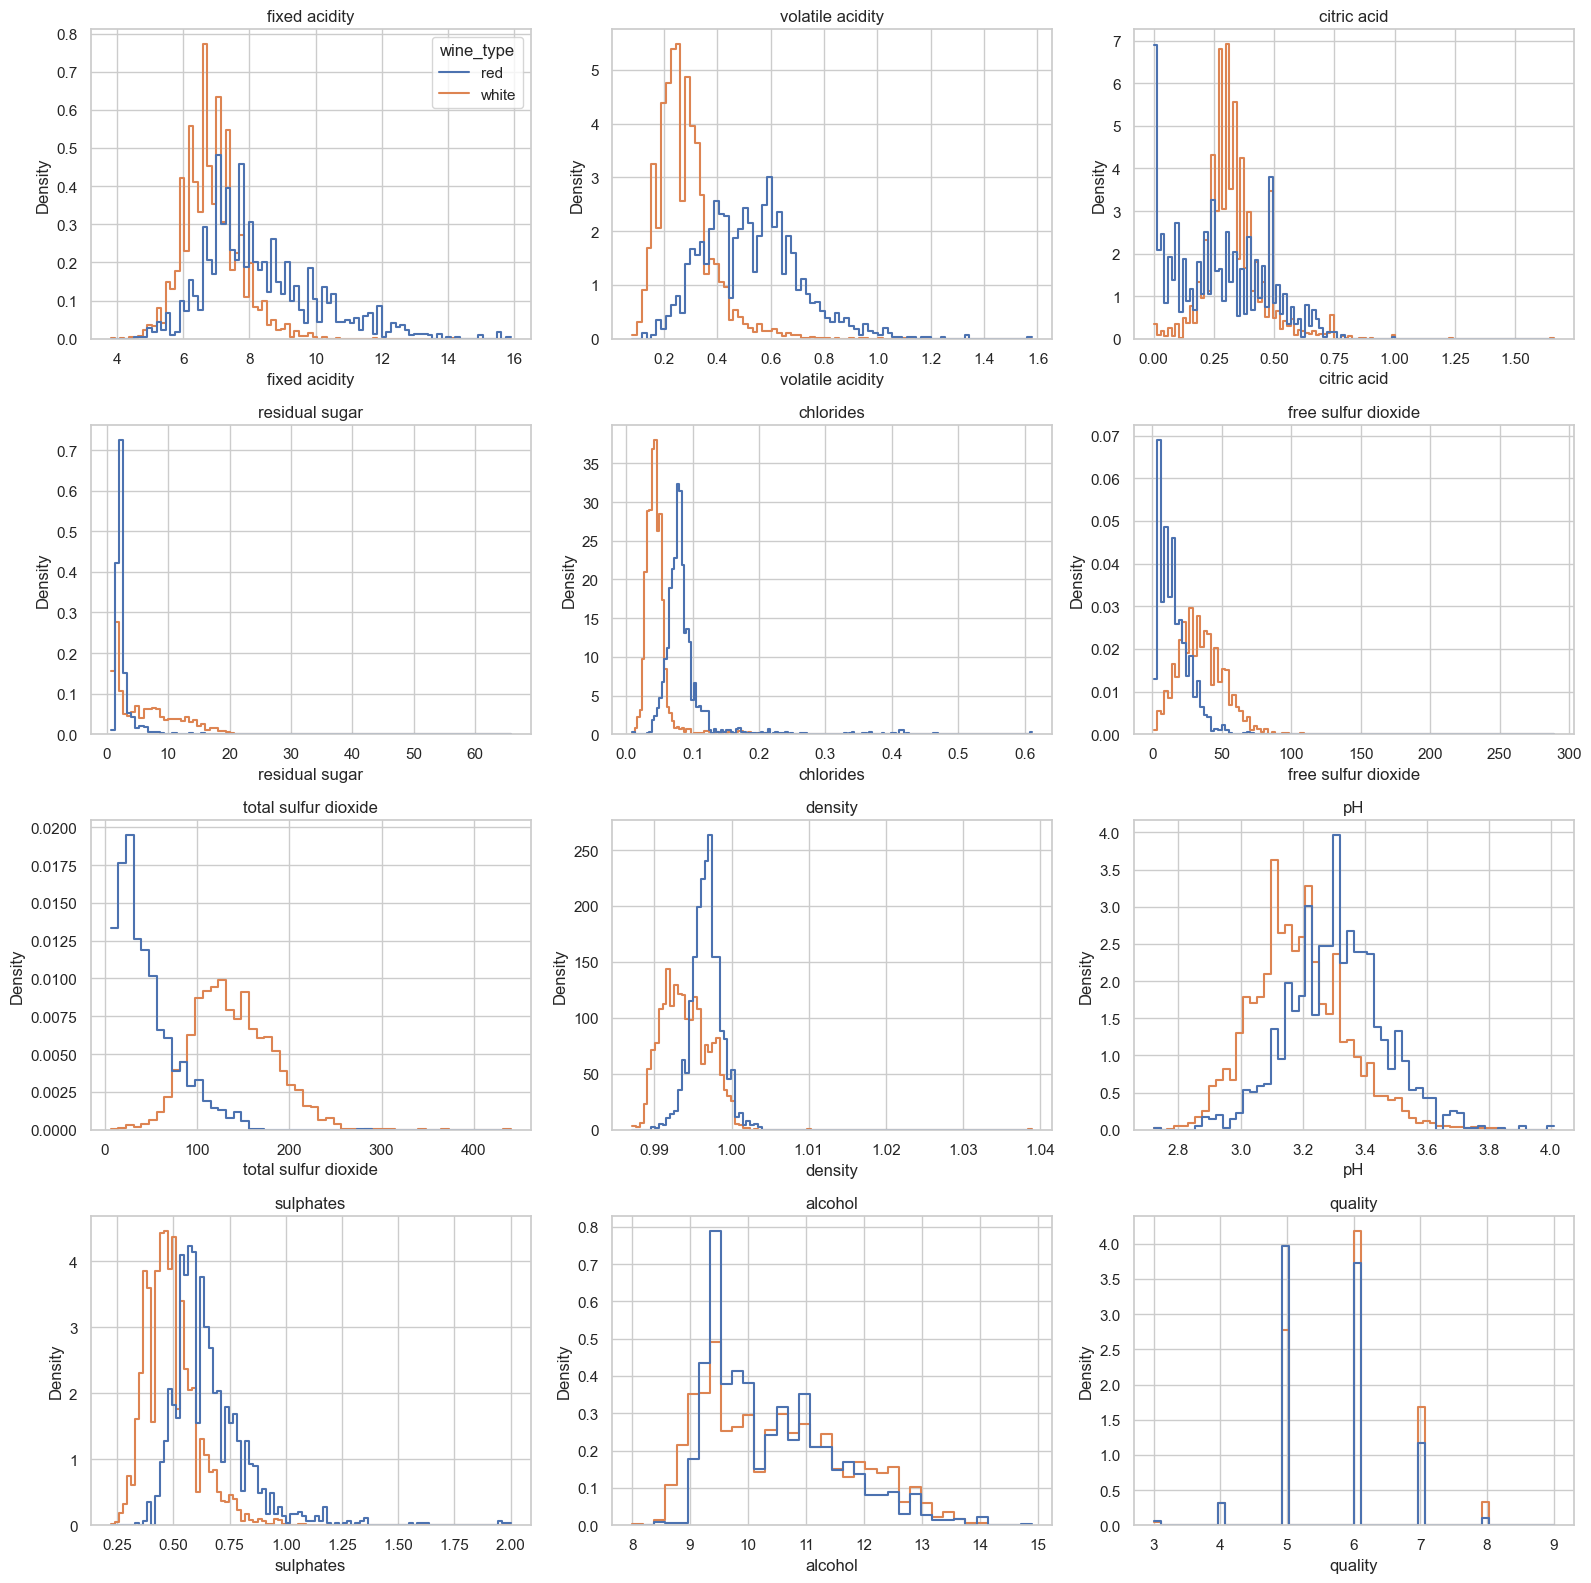

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for index, (ax, column) in enumerate(zip(axes.flat, numeric_cols)):
    sns.histplot(
        data=wines,
        x=column,
        hue="wine_type",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        legend=index == 0,
        ax=ax,
    )
    ax.set_title(column)

fig.tight_layout()
plt.show()

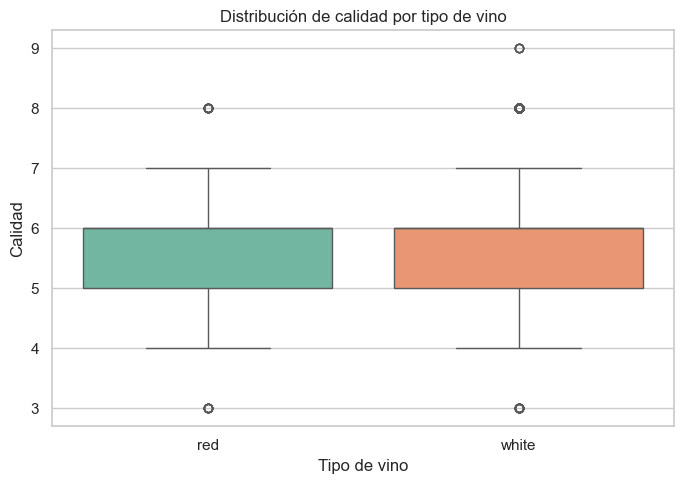

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(
    data=wines,
    x="wine_type",
    y="quality",
    hue="wine_type",
    palette="Set2",
    legend=False,
    ax=ax,
)
ax.set(title="Distribución de calidad por tipo de vino", xlabel="Tipo de vino", ylabel="Calidad")
fig.tight_layout()
plt.show()

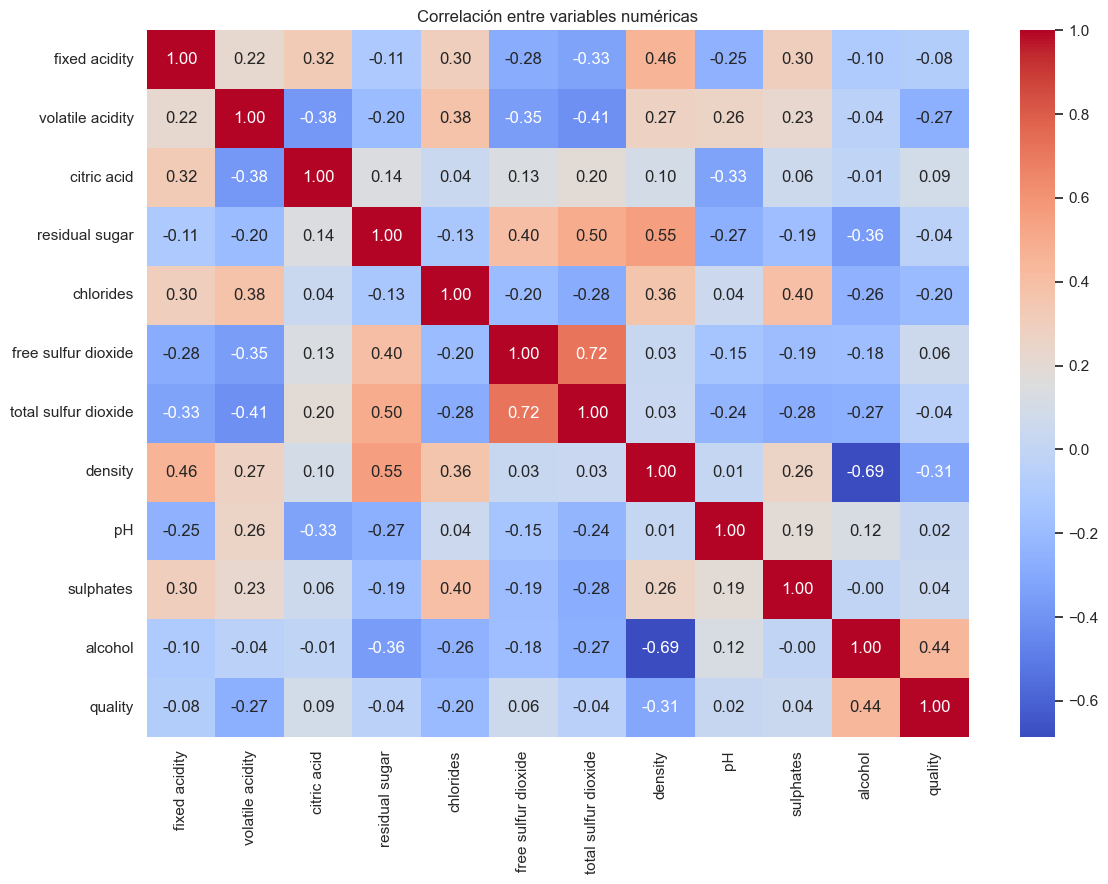

In [7]:
correlations = wines[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=ax,
)
ax.set_title("Correlación entre variables numéricas")
fig.tight_layout()
plt.show()

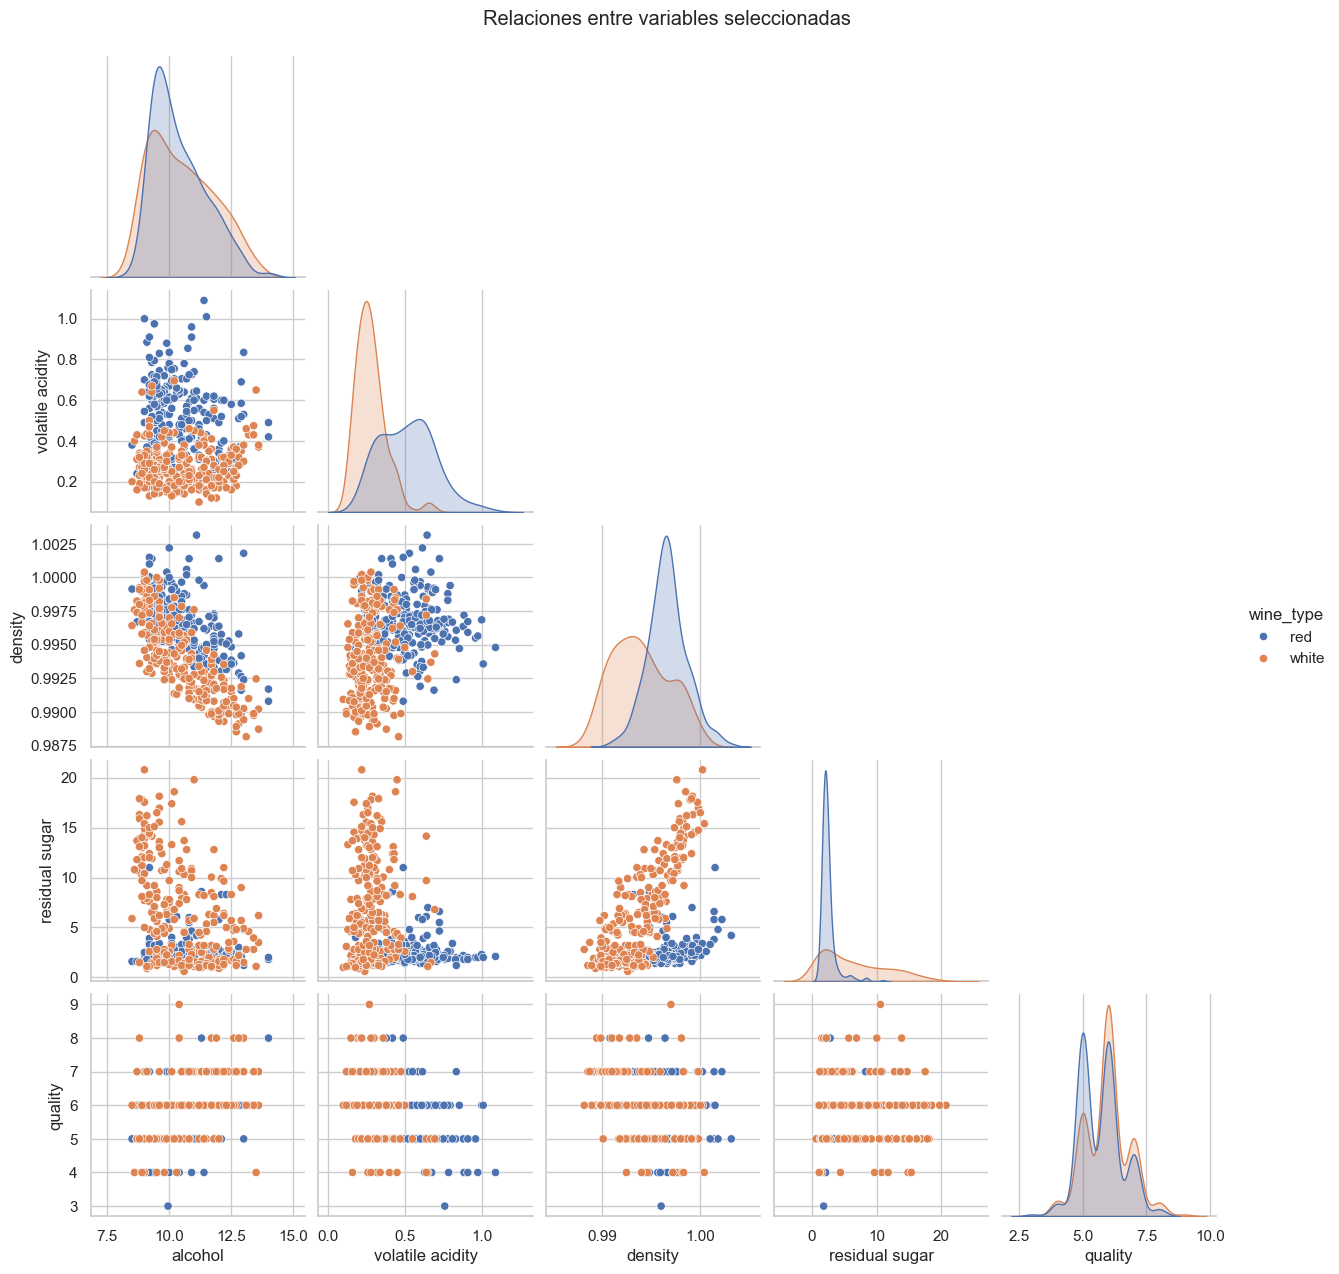

In [8]:
pairplot_cols = ["alcohol", "volatile acidity", "density", "residual sugar", "quality"]
pairplot_data = wines.groupby("wine_type", group_keys=False).sample(n=250, random_state=42)

pairplot = sns.pairplot(
    pairplot_data,
    vars=pairplot_cols,
    hue="wine_type",
    corner=True,
)
pairplot.figure.suptitle("Relaciones entre variables seleccionadas", y=1.02)
plt.show()

### Observaciones

- Las distribuciones varían por tipo: los vinos blancos tienden a mostrar más azúcar residual y dióxido de azufre; los tintos, mayor acidez volátil y cloruros.
- La distribución de quality es muy similar para ambos tipos de vinos.
- La calidad se concentra principalmente entre 5 y 6 para ambos tipos. Muy similares.
- En la matriz combinada, alcohol y calidad presentan una correlación positiva moderada (0.44), mientras que densidad y alcohol muestran una correlación negativa marcada (-0.69). El dióxido de azufre libre y el total también se relacionan positivamente (0.72).
- Realmente no hay muchas variables linealmente correlacionadas con quality.

## Paso 3: limpieza de datos

Decisiones para este dataset:
- no imputar ni eliminar valores faltantes porque no se encontraron
- eliminar únicamente filas completamente idénticas dentro del mismo tipo de vino (240 en tintos y 937 en blancos), conservando la primera aparición
- conservar los valores extremos detectados por IQR porque son candidatos estadísticos, no errores confirmados
- convertir las columnas numéricas explícitamente y `wine_type` a categórica. No se eliminarán duplicados aproximados ni se recortarán valores.

In [9]:
numeric_cols = wines.select_dtypes(include="number").columns.tolist()
continuous_cols = [column for column in numeric_cols if column != "quality"]

missing_counts = wines.isna().sum()
duplicate_counts = pd.Series(
    {
        wine_type: group.duplicated().sum()
        for wine_type, group in wines.groupby("wine_type", observed=True)
    },
    name="filas duplicadas exactas",
)

outlier_counts = {}
for wine_type, group in wines.groupby("wine_type", observed=True):
    q1 = group[continuous_cols].quantile(0.25)
    q3 = group[continuous_cols].quantile(0.75)
    spread = q3 - q1
    outlier_counts[wine_type] = (
        (group[continuous_cols] < q1 - 1.5 * spread)
        | (group[continuous_cols] > q3 + 1.5 * spread)
    ).sum()

print("Valores faltantes por variable")
display(missing_counts.rename("faltantes").to_frame())
print("Duplicados exactos por tipo de vino")
display(duplicate_counts.to_frame())
print("Valores fuera de 1.5 IQR por variable y tipo")
display(pd.DataFrame(outlier_counts).T.rename_axis("wine_type"))

Valores faltantes por variable


,faltantes
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicados exactos por tipo de vino


,filas duplicadas exactas
red,240
white,937


Valores fuera de 1.5 IQR por variable y tipo


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
wine_type,,,,,,,,,,,
red,49,19,1,155,112,30,55,45,35,59,13
white,119,186,270,7,208,50,19,5,75,124,0


In [10]:
wines_clean = wines.copy()

for column in numeric_cols:
    wines_clean[column] = pd.to_numeric(wines_clean[column], errors="raise")

if wines_clean["quality"].mod(1).ne(0).any():
    raise ValueError("La variable quality contiene valores no enteros.")
if wines_clean.isna().any().any():
    raise ValueError("Se encontraron valores faltantes; revisar antes de continuar.")

wines_clean["quality"] = wines_clean["quality"].astype("int64")
wines_clean["wine_type"] = wines_clean["wine_type"].astype("category")

rows_before = len(wines_clean)
duplicates_removed = int(wines_clean.duplicated().sum())
wines_clean = wines_clean.drop_duplicates(keep="first").reset_index(drop=True)

print(f"Registros iniciales: {rows_before:,}")
print(f"Duplicados exactos eliminados: {duplicates_removed:,}")
print(f"Registros después de limpiar: {len(wines_clean):,}")
print(f"Valores faltantes después de limpiar: {wines_clean.isna().sum().sum()}")
display(wines_clean.dtypes.rename("tipo final").to_frame())

Registros iniciales: 6,497
Duplicados exactos eliminados: 1,177
Registros después de limpiar: 5,320
Valores faltantes después de limpiar: 0


,tipo final
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


## Paso 4: entrenamiento de un modelo baseline

`quality` es una puntuación numérica ordenada, por lo que se plantea como regresión. La regresión lineal es un baseline válido porque es un modelo supervisado simple e interpretable: permite comprobar si las variables fisicoquímicas y el tipo de vino capturan una relación lineal con la calidad antes de probar modelos más complejos. Su propósito es establecer una referencia reproducible, no asumir que será el modelo con mejor desempeño.

Se separará el conjunto limpio en 80 % para entrenamiento y 20 % para prueba, con semilla fija. `wine_type` se codificará como variable categórica. Como `quality` es discreta y ordinal, la regresión asume distancias uniformes entre puntuaciones y puede producir valores decimales; por eso se evalúa con métricas de error en puntos y se interpretan sus resultados con esa limitación.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = wines_clean.drop(columns="quality")
y = wines_clean["quality"]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = ["wine_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
    ],
    remainder="passthrough",
)

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ]
)
baseline_model.fit(X_train, y_train)

print(f"Entrenamiento: {len(X_train):,} filas")
print(f"Prueba: {len(X_test):,} filas")

Entrenamiento: 4,256 filas
Prueba: 1,064 filas


## Paso 5: evaluación del modelo

Se evaluará sobre el 20 % reservado para prueba, que el modelo no usó durante el entrenamiento. MAE y RMSE miden el error en puntos de calidad; R² compara el modelo con una referencia que predice la media de la calidad del conjunto de prueba. También se reportará qué proporción de predicciones queda a no más de un punto del valor observado.

In [12]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = baseline_model.predict(X_test)
absolute_errors = np.abs(y_test.to_numpy() - y_pred)

evaluation = pd.Series(
    {
        "MAE (puntos)": mean_absolute_error(y_test, y_pred),
        "RMSE (puntos)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "Predicciones dentro de ±1 punto (%)": (absolute_errors <= 1).mean() * 100,
    },
    name="prueba",
)
display(evaluation.to_frame())
print(f"Calidad media en prueba: {y_test.mean():.2f}")
print(f"Rango observado en prueba: {y_test.min()} a {y_test.max()}")

,prueba
MAE (puntos),0.560200
RMSE (puntos),0.720792
R2,0.309003
Predicciones dentro de ±1 punto (%),86.842105


Calidad media en prueba: 5.82
Rango observado en prueba: 3 a 9


### Interpretación

- **MAE = 0.56 puntos:** en promedio, la predicción se desvía algo más de medio punto de la puntuación observada. Como `quality` toma valores enteros, el error medio es menor que un nivel completo de calidad, aunque no significa que cada predicción quede a medio punto.
- **RMSE = 0.72 puntos:** también expresa error en puntos y penaliza más los errores grandes. Al superar al MAE, indica que algunos errores mayores elevan el promedio cuadrático; conviene revisar sus residuos en una evaluación posterior.
- **R² = 0.31:** el modelo captura alrededor del 31 % de la variación de `quality` en el conjunto de prueba frente a la referencia basada en la media de ese conjunto. Cerca del 69 % de la variación queda sin explicar, por lo que la capacidad explicativa es limitada.
- **Dentro de ±1 punto = 86.8 %:** aproximadamente 87 de cada 100 predicciones quedan a un punto o menos de la puntuación real; alrededor de 13 de cada 100 se desvían por más de un punto.

En conjunto, el error absoluto resulta relativamente pequeño respecto a la escala observada en prueba (de 3 a 9), pero el R² muestra que la regresión lineal solo explica una parte de las diferencias entre vinos. Es un punto de comparación sencillo, no evidencia de que el modelo sea suficiente para uso operativo. Además, al tratar `quality` como regresión, el modelo puede producir puntuaciones decimales y asume distancias uniformes entre niveles; una mejora futura debería compararse con este mismo split y evaluar también un modelo no lineal u ordinal.

## Paso 6: registro del experimento en MLflow

Se registrarán el tipo de modelo, la configuración de la partición y las métricas calculadas sobre prueba. También aplica guardar el pipeline entrenado que en este caso es principalmente la codificación de `wine_type` junto con la regresión, por lo que puede recuperarse para reproducir predicciones.

In [13]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

experiment_name = "TC5061_Wine_Quality_Baseline"
mlflow.set_experiment(experiment_name)

model_example = X_train.head(5).copy()
model_example["wine_type"] = model_example["wine_type"].astype(str)
model_signature = infer_signature(
    model_example,
    baseline_model.predict(model_example),
)

with mlflow.start_run(run_name="linear_regression_baseline") as run:
    mlflow.log_params(
        {
            "model_type": "LinearRegression",
            "target": "quality",
            "test_size": 0.2,
            "random_state": 42,
            "training_rows": len(X_train),
            "test_rows": len(X_test),
            "numeric_features": ",".join(numeric_features),
            "categorical_features": ",".join(categorical_features),
        }
    )
    mlflow.log_metrics(
        {
            "mae": float(evaluation.loc["MAE (puntos)"]),
            "rmse": float(evaluation.loc["RMSE (puntos)"]),
            "r2": float(evaluation.loc["R2"]),
            "within_one_point_pct": float(
                evaluation.loc["Predicciones dentro de ±1 punto (%)"]
            ),
        }
    )
    model_info = mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="baseline_model",
        signature=model_signature,
        input_example=model_example,
    )

print(f"MLflow: {mlflow.__version__}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experimento: {experiment_name}")
print(f"Run ID: {run.info.run_id}")
print(f"Modelo registrado en: {model_info.model_uri}")

/opt/anaconda3/envs/msaai/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: 3.16.1
Tracking URI: sqlite:////Users/beibibumer/Desktop/msaai/4/mlops/act2/mlflow.db
Experimento: TC5061_Wine_Quality_Baseline
Run ID: 4dcf85fd5ca2463a87f6d6359b305292
Modelo registrado en: models:/m-3941dd60fab7467ba06a6e3c5c6c3ee4


## Paso 7: reflexión

Este ejercicio construye un flujo funcional de análisis, limpieza, entrenamiento, evaluación y registro, pero todavía puede fortalecerse.

Primero, versionaría los datos, el código y las dependencias para poder reconstruir exactamente cada ejecución. También agregaría pruebas automáticas para validar el esquema, los rangos y las transformaciones, además de comparar la regresión lineal con un `DummyRegressor` y otros modelos mediante validación cruzada. Así sabríamos si la complejidad adicional mejora el desempeño de forma consistente y no solo en una partición.
En MLflow, reemplazaría el almacenamiento local por un backend y un almacén de artefactos compartidos, y registraría la versión del dataset y del código. Antes de desplegar, definiría criterios de aceptación, revisión del modelo y un plan para monitorear cambios en los datos y en el error, con alertas y reglas de reentrenamiento.

En el ámbito profesional de datos y MLOps, estas prácticas permiten explicar de dónde viene, cómo se obtuvo y si puede reproducirse un resultado. La trazabilidad facilita colaborar entre análisis, ingeniería y áreas usuarias; las pruebas y la evaluación independiente reducen errores que podrían afectar decisiones reales. También obliga a traducir métricas técnicas, como MAE y R², a consecuencias comprensibles para quienes usarán el sistema. Este aprendizaje es aplicable a cualquier dominio que transforme datos en recomendaciones o predicciones: un modelo útil debe ser medible, auditable, mantenible y monitoreado durante todo su ciclo de vida.